# Лабораторная работа 16

Тема: **Vision Transformer (ViT) для классификации изображений CIFAR-10**  
Формат: практическая работа с обязательными собственными экспериментами и комментариями.

> Этот ноутбук специально оформлен так, чтобы его нельзя было автоматически заполнить генеративной моделью без реального запуска экспериментов и анализа.  
> Каркас кода дан, но **основные баллы** ставятся за ваши настройки, графики и живые текстовые объяснения.


## 1. Ваши ожидания от ViT в сравнении с CNN

В Лабораторной работе 8 мы решали задачу классификации CIFAR-10 с помощью свёрточных сетей (CNN). Теперь мы применим архитектуру, изначально созданную для текстов (Transformer).

Перед началом работы зафиксируйте своё понимание (6-10 предложений):

1. В чем главное отличие того, как CNN и ViT «смотрят» на картинку? (Вспомните про локальные признаки в свертках и глобальное внимание в Трансформерах).
2. Зачем изображение нарезается на непересекающиеся "патчи" (patches), а не подается в Трансформер попиксельно?
3. Ожидаете ли вы, что простой самодельный ViT побьет вашу CNN из 8-й лабораторной при обучении "с нуля" на небольшом датасете? Почему?

In [9]:
intro_text = """
1. Свёрточная сеть работает локально обрабатывает небольшой участок (например, 3x3 пикселя).
Понимание картинки складывается постепенно, слой за слоем. 
ViT с первого же слоя видит все патчи сразу через механизм self-attention.
2. Количество пикселей в 32x32 картинке - 1024. Обрабатывать их как отдельные токены было бы сложно и долго. 
3. Ожидаю, что самодельный ViT при обучении с нуля проиграет CNN. Причина - малый объем изображений. 
"""
print(intro_text)


1. Свёрточная сеть работает локально обрабатывает небольшой участок (например, 3x3 пикселя).
Понимание картинки складывается постепенно, слой за слоем. 
ViT с первого же слоя видит все патчи сразу через механизм self-attention.
2. Количество пикселей в 32x32 картинке - 1024. Обрабатывать их как отдельные токены было бы сложно и долго. 
3. Ожидаю, что самодельный ViT при обучении с нуля проиграет CNN. Причина - малый объем изображений. 



## 2. Импорт библиотек и настройка среды

Сделаем стандартные шаги, аналогичные Лабораторной 8.

In [1]:
import torch
from torch import nn
from torch.utils.data import DataLoader
import torchvision
from torchvision import datasets, transforms
import matplotlib.pyplot as plt
import numpy as np
from tqdm import tqdm

# Ваш личный seed (заполните его, можно взять тот же, что в Лаб 8)
MY_SEED = 1
torch.manual_seed(MY_SEED)
np.random.seed(MY_SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Устройство:", device)
print("MY_SEED =", MY_SEED)

Устройство: cpu
MY_SEED = 1


## 3. CIFAR‑10: загрузка и нормализация

Используем те же параметры нормализации, что и для CNN.

In [2]:
batch_size = 128  # при выполнении работы попробуйте изменить

transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.4914, 0.4822, 0.4465),
                         (0.2470, 0.2435, 0.2616))
])

train_dataset = datasets.CIFAR10(root="./data", train=True, download=True, transform=transform)
test_dataset = datasets.CIFAR10(root="./data", train=False, download=True, transform=transform)

train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

classes = train_dataset.classes
print("Классы CIFAR‑10:", classes)
print("Размер train:", len(train_dataset))
print("Размер test :", len(test_dataset))

c:\Users\Иван\Desktop\ВУЗ\4 курс\Нейронные сети\.venv\Lib\site-packages\torchvision\datasets\cifar.py:83: VisibleDeprecationWarning: dtype(): align should be passed as Python or NumPy boolean but got `align=0`. Did you mean to pass a tuple to create a subarray type? (Deprecated NumPy 2.4)
  entry = pickle.load(f, encoding="latin1")


Классы CIFAR‑10: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']
Размер train: 50000
Размер test : 10000


### Краткий комментарий по данным

В Лабораторной 8 вы уже описывали датасет. Сейчас ответьте на другой вопрос (3-5 предложений):
Размер картинок в CIFAR-10 — 32x32 пикселя. Если мы выберем размер патча для ViT равным 8x8, на сколько токенов (патчей) будет разбита одна картинка? А если размер патча будет 16x16? Хватит ли Трансформеру такого количества токенов для понимания смысла картинки?

In [8]:
data_comment = """
1. При размере патча 8x8 картинка разбивается на 16 патчей.
2. При размере патча 16x16 мы получим всего 4 патча.
3. Четыре токена это очень мало. 
Трансформер будет использовать четыре грубые квадрантами картинки и не сможет уловить детали объектов.
Поэтому вариант с patch_size=8 (16 токенов) лучше.
"""
print(data_comment)


1. При размере патча 8x8 картинка разбивается на 16 патчей.
2. При размере патча 16x16 мы получим всего 4 патча.
3. Четыре токена это очень мало. 
Трансформер будет использовать четыре грубые квадрантами картинки и не сможет уловить детали объектов.
Поэтому вариант с patch_size=8 (16 токенов) лучше.



## 4. Архитектура Vision Transformer

В этой лабораторной мы пишем **Micro-ViT**. Картинка превращается в последовательность векторов с помощью свертки (Patch Embedding), к ней добавляется позиционное кодирование и специальный `[CLS]` токен, после чего всё это обрабатывается стандартным Transformer Encoder.

In [3]:
class PatchEmbedding(nn.Module):
    def __init__(self, in_channels=3, patch_size=8, embed_dim=64, img_size=32):
        super().__init__()
        self.patch_size = patch_size
        # Считаем количество патчей. Для 32x32 и патча 8x8 это (32/8) * (32/8) = 16
        self.num_patches = (img_size // patch_size) ** 2
        
        # Свертка без перекрытий: размер ядра и шаг равны размеру патча
        self.proj = nn.Conv2d(in_channels, embed_dim, kernel_size=patch_size, stride=patch_size)

    def forward(self, x):
        # x shape: (B, C, H, W)
        x = self.proj(x)           # -> (B, embed_dim, H/P, W/P)
        x = x.flatten(2)           # -> (B, embed_dim, num_patches)
        x = x.transpose(1, 2)      # -> (B, num_patches, embed_dim)
        return x

class SimpleViT(nn.Module):
    def __init__(self, in_channels=3, patch_size=8, embed_dim=64, img_size=32, num_classes=10, depth=2, heads=4):
        super().__init__()
        self.patch_embed = PatchEmbedding(in_channels, patch_size, embed_dim, img_size)
        
        # [CLS] токен (обучаемый параметр)
        self.cls_token = nn.Parameter(torch.zeros(1, 1, embed_dim))
        # Обучаемые позиционные эмбеддинги (длина = количество патчей + 1 для CLS)
        self.pos_embed = nn.Parameter(torch.zeros(1, 1 + self.patch_embed.num_patches, embed_dim))
        
        # Блок Трансформера
        encoder_layer = nn.TransformerEncoderLayer(
            d_model=embed_dim, 
            nhead=heads, 
            dim_feedforward=embed_dim * 4, 
            dropout=0.1, 
            batch_first=True
        )
        self.transformer = nn.TransformerEncoder(encoder_layer, num_layers=depth)
        
        # Итоговый классификатор
        self.mlp_head = nn.Sequential(
            nn.LayerNorm(embed_dim),
            nn.Linear(embed_dim, num_classes)
        )

    def forward(self, x):
        B = x.shape[0]
        
        # 1. Извлекаем патчи
        x = self.patch_embed(x)                        # (B, num_patches, embed_dim)
        
        # 2. Добавляем [CLS] токен
        cls_tokens = self.cls_token.expand(B, -1, -1)  # (B, 1, embed_dim)
        x = torch.cat((cls_tokens, x), dim=1)          # (B, num_patches + 1, embed_dim)
        
        # 3. Добавляем позиционное кодирование
        x = x + self.pos_embed                         
        
        # 4. Пропускаем через Transformer
        x = self.transformer(x)                        
        
        # 5. Классификация по выходу [CLS] токена (индекс 0)
        cls_out = x[:, 0]                              
        return self.mlp_head(cls_out)

# Базовые настройки (для быстрого обучения на ЦПУ)
patch_size = 8
embed_dim = 64
depth = 2
heads = 4

model = SimpleViT(patch_size=patch_size, embed_dim=embed_dim, depth=depth, heads=heads).to(device)
print(model)
print(f"Количество параметров: {sum(p.numel() for p in model.parameters())}")

SimpleViT(
  (patch_embed): PatchEmbedding(
    (proj): Conv2d(3, 64, kernel_size=(8, 8), stride=(8, 8))
  )
  (transformer): TransformerEncoder(
    (layers): ModuleList(
      (0-1): 2 x TransformerEncoderLayer(
        (self_attn): MultiheadAttention(
          (out_proj): NonDynamicallyQuantizableLinear(in_features=64, out_features=64, bias=True)
        )
        (linear1): Linear(in_features=64, out_features=256, bias=True)
        (dropout): Dropout(p=0.1, inplace=False)
        (linear2): Linear(in_features=256, out_features=64, bias=True)
        (norm1): LayerNorm((64,), eps=1e-05, elementwise_affine=True)
        (norm2): LayerNorm((64,), eps=1e-05, elementwise_affine=True)
        (dropout1): Dropout(p=0.1, inplace=False)
        (dropout2): Dropout(p=0.1, inplace=False)
      )
    )
  )
  (mlp_head): Sequential(
    (0): LayerNorm((64,), eps=1e-05, elementwise_affine=True)
    (1): Linear(in_features=64, out_features=10, bias=True)
  )
)
Количество параметров: 114250


### Ваш комментарий к архитектуре

Ответьте коротко:

- Для чего в архитектуру внедрен обучаемый `[CLS]` токен и почему мы передаем в финальный `nn.Linear` именно его, а не усредненные значения всех патчей?
- В CNN (Лабораторная 8) мы не использовали Positional Encoding. Почему здесь он жизненно необходим?

In [ ]:
arch_comment = """
1. CLS-токен это обучаемый вектор, который добавляется в начало последовательности перед всеми патчами. 
После прохождения через все слои Трансформера он накапливает агрегированную информацию обо всей картинке через механизм self-attention.
CLS специально "обучается" быть глобальным представлением изображения для задачи классификации.
2. Без Positional Encoding ViT не отличал бы пространственное расположение патчей.
"""
print(arch_comment)

## 5. Функция потерь, оптимизатор и цикл обучения

Здесь код практически идентичен Лабораторной 8. ViT чувствителен к скорости обучения (learning rate), поэтому используем AdamW (рекомендованный для ViT) вместо обычного Adam.

In [4]:
criterion = nn.CrossEntropyLoss()
learning_rate = 1e-3
# Для ViT AdamW часто работает лучше обычного Adam за счет правильной регуляризации весов
optimizer = torch.optim.AdamW(model.parameters(), lr=learning_rate, weight_decay=1e-4)

def train_one_epoch(model, dataloader, optimizer, criterion, device):
    model.train()
    total_loss, total_correct, total = 0.0, 0, 0

    for images, labels in tqdm(dataloader, desc="Обучение", leave=False):
        images, labels = images.to(device), labels.to(device)

        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        
        # Клиппинг градиентов помогает стабилизировать обучение Трансформеров
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        optimizer.step()

        total_loss += loss.item() * images.size(0)
        preds = outputs.argmax(dim=1)
        total_correct += (preds == labels).sum().item()
        total += images.size(0)

    return total_loss / total, total_correct / total

def evaluate(model, dataloader, criterion, device):
    model.eval()
    total_loss, total_correct, total = 0.0, 0, 0

    with torch.no_grad():
        for images, labels in dataloader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            loss = criterion(outputs, labels)

            total_loss += loss.item() * images.size(0)
            preds = outputs.argmax(dim=1)
            total_correct += (preds == labels).sum().item()
            total += images.size(0)

    return total_loss / total, total_correct / total

## 6. Обучение базовой модели

Запустим обучение на 5 эпох. Из-за малого размера модели одна эпоха на ЦПУ должна обучаться меньше 1 минуты (около 30 сек).

Эпоха 1/5 | Train Loss: 1.8466, Acc: 0.3178 | Test Loss: 1.6666, Acc: 0.3888


Эпоха 2/5 | Train Loss: 1.6124, Acc: 0.4042 | Test Loss: 1.5026, Acc: 0.4479


Эпоха 3/5 | Train Loss: 1.4808, Acc: 0.4604 | Test Loss: 1.4020, Acc: 0.4875


Эпоха 4/5 | Train Loss: 1.3939, Acc: 0.4928 | Test Loss: 1.3532, Acc: 0.5088


Эпоха 5/5 | Train Loss: 1.3339, Acc: 0.5148 | Test Loss: 1.2904, Acc: 0.5322


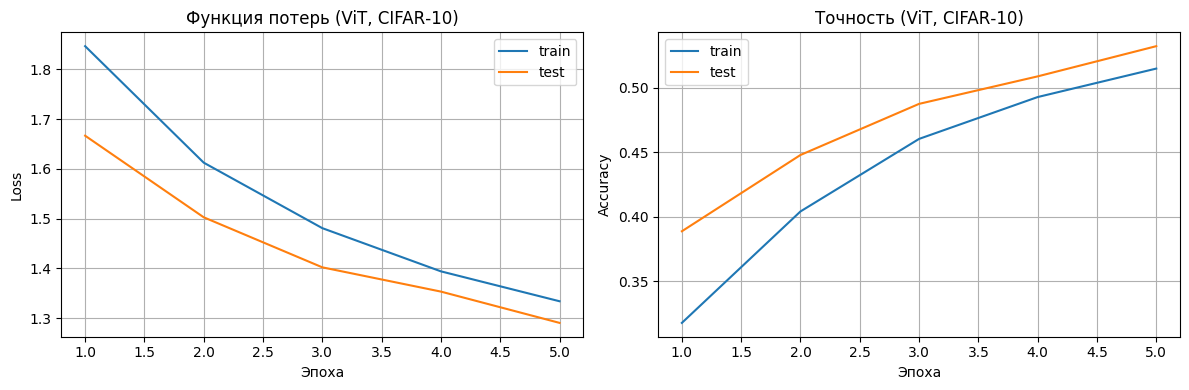

In [5]:
num_epochs = 5  # Начните с 5, для финального отчета можно увеличить до 10-15

history = {"train_loss": [], "train_acc": [], "test_loss": [], "test_acc": []}

for epoch in range(1, num_epochs + 1):
    train_loss, train_acc = train_one_epoch(model, train_loader, optimizer, criterion, device)
    test_loss, test_acc = evaluate(model, test_loader, criterion, device)

    history["train_loss"].append(train_loss)
    history["train_acc"].append(train_acc)
    history["test_loss"].append(test_loss)
    history["test_acc"].append(test_acc)

    print(f"Эпоха {epoch}/{num_epochs} | "
          f"Train Loss: {train_loss:.4f}, Acc: {train_acc:.4f} | "
          f"Test Loss: {test_loss:.4f}, Acc: {test_acc:.4f}")

# Отрисовка графиков (аналогично Лаб 8)
epochs = np.arange(1, num_epochs + 1)
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(epochs, history["train_loss"], label="train")
plt.plot(epochs, history["test_loss"], label="test")
plt.xlabel("Эпоха")
plt.ylabel("Loss")
plt.title("Функция потерь (ViT, CIFAR‑10)")
plt.grid(True)
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(epochs, history["train_acc"], label="train")
plt.plot(epochs, history["test_acc"], label="test")
plt.xlabel("Эпоха")
plt.ylabel("Accuracy")
plt.title("Точность (ViT, CIFAR‑10)")
plt.grid(True)
plt.legend()

plt.tight_layout()
plt.show()

### Анализ кривых обучения в сравнении с CNN

Опишите в 6–8 предложениях:

- Какую точность выдал базовый ViT за 5 эпох? Сравните эту цифру с точностью вашей CNN из Лабораторной работы 8 на том же этапе обучения.
- Заметно ли сильное переобучение (overfitting) у Трансформера?
- Почему обучение ViT "с нуля" на 50 000 картинок часто проигрывает классической CNN?

In [7]:
training_analysis = """
1. ViT за 5 эпох достигает точности 53%. CNN из лабараторной 8 достигает к 5 эпохе 77%.
2. Нет, переобучение не наблюдается. Оба показателя на test и train практически не расходятся. 
Можно даже сказать, что показатели начинаются сходиться. 
3. Потому что, ввиду разных архитектур, CNN умеет с самого начала обнаруживать текстуры благодаря сверткам.
ViT же учится позиционным зависимостям полностью из данных. 50.000 изображений для него мало.
"""
print(training_analysis)


1. ViT за 5 эпох достигает точности 53%. CNN из лабараторной 8 достигает к 5 эпохе 77%.
2. Нет, переобучение не наблюдается. Оба показателя на test и train практически не расходятся. 
Можно даже сказать, что показатели начинаются сходиться. 
3. Потому что, ввиду разных архитектур, CNN умеет с самого начала обнаруживать текстуры благодаря сверткам.
ViT же учится позиционным зависимостям полностью из данных. 50.000 изображений для него мало.



## 7. Эксперименты по улучшению модели

В **самостоятельной** части лабораторной вы должны:

1. Изменить размер патча: попробуйте `patch_size = 4` (64 токена) и `patch_size = 16` (4 токена). Как размер патча влияет на точность и время обучения одной эпохи?
2. Попробовать сделать сеть глубже (`depth = 4` или `6`) и шире (`embed_dim = 128`).
3. (Опционально) Добавить аугментации данных (RandomCrop, RandomHorizontalFlip) в `transform` при загрузке `train_dataset`. Трансформеры сильно зависят от объема данных, поэтому аугментация для них критически важна.

Сравните **минимум два** варианта архитектуры ViT.

## 8. Итоговые выводы по лабораторной

В конце опишите:

- Какой вариант гиперпараметров ViT (`patch_size`, `depth`, `embed_dim`) оказался самым удачным?
- Кто победил в итоге: CNN из Лабораторной 8 или ViT из Лабораторной 16 при обучении с нуля на CIFAR-10?
- В каких реальных задачах (и при каких объемах данных) вы бы стали применять Vision Transformer, а когда отдали бы предпочтение CNN?


In [6]:
final_summary = """
1. Наилучшая конфигурация (patch_size=4, embed_dim=128, depth=4) с аугментацией (RandomCrop,RandomHorizontalFlip)  
дало точность 55% после 5 эпох. Аугментация была применена, так как она еще больше увеличивает сходимость кривых.
2. Считаю, что в сравнении победила CNN, так как при аналогичном количестве эпох она достигает  куда большей точности (77%) 
Это обусловлено тем, что датасет недостаточен для ViT.
3. Vision Transformer стоит применять в задачах с большими объёмами данных (сотни тысяч
и более изображений) или при наличии предобученных весов.
"""
print(final_summary)


1. Наилучшая конфигурация (patch_size=4, embed_dim=128, depth=4) с аугментацией (RandomCrop,RandomHorizontalFlip)  
дало точность 55% после 5 эпох. Аугментация была применена, так как она еще больше увеличивает сходимость кривых.
2. Считаю, что в сравнении победила CNN, так как при аналогичном количестве эпох она достигает  куда большей точности (77%) 
Это обусловлено тем, что датасет недостаточен для ViT.
3. Vision Transformer стоит применять в задачах с большими объёмами данных (сотни тысяч
и более изображений) или при наличии предобученных весов.

